In [2]:
import random
import numpy as np
import statsmodels as sm
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
colors_blindness = sns.color_palette("colorblind")

# Création des données

On démarre par créer des données homo et hétéro scédastiques. On crée aussi les vraies données.

In [ ]:
np.random.seed(43)

n = 300
X = np.random.uniform(low=0,high=5,size=n)
sigma = 0.5

## Homoscedastic model
Y_hom = np.cos(X) + sigma*np.random.normal(size=n)

y_true = np.cos(np.linspace(0,5,300))

## Heteroscedastic model
y = np.cos(X) + (1-np.cos(X))*sigma*np.random.normal(size=n)



color_train = colors_blindness[1]
color_true = colors_blindness[4]
color_cal = colors_blindness[9]
color_test = colors_blindness[7]

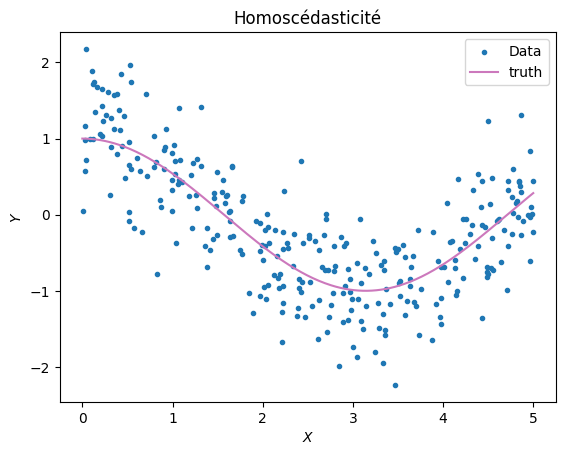

In [ ]:
plt.scatter(X,Y_hom,marker='.', label = "Data")
plt.plot(np.linspace(0,5,300),y_true, color = color_true, label ="truth")
plt.xlabel(r'$X$')
plt.ylabel(r'$Y$')
plt.title('Homoscédasticité')
plt.legend()
plt.show()

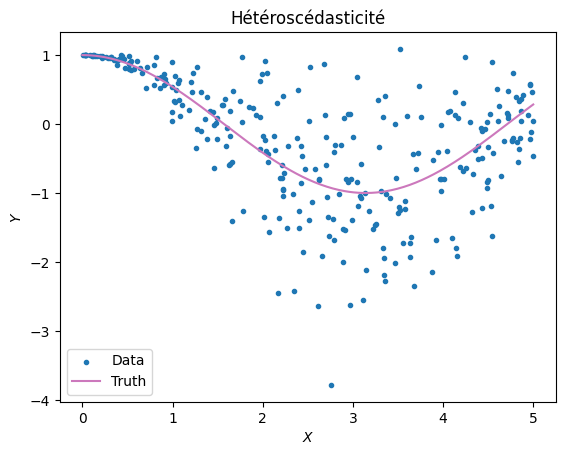

In [ ]:
plt.scatter(X,y,marker='.', label = "Data")
plt.plot(np.linspace(0,5,300),y_true, color = color_true, label = "Truth")
plt.xlabel(r'$X$')
plt.ylabel(r'$Y$')
plt.title('Hétéroscédasticité')
plt.legend()
plt.show()

# Préparation des modèles

On sépare nos données en train/test, puis on configure la régression polynomiales en créant le tableau de variables $(1,X,X^2,X^3)$

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.33,
                                                    random_state=42)

In [ ]:
# Data preparation (embedding)

from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(4)
Xpoly_train =  poly.fit_transform(X_train[:, np.newaxis])
Xpoly_test  =  poly.fit_transform(X_test[:, np.newaxis])

# Regression polynomiale standard

On fitte une régression polynomiale sur les données polynomiales.

In [ ]:
from sklearn.linear_model import LinearRegression

linear_reg = LinearRegression(fit_intercept=False)

# Fit linear regression
#
linear_reg.fit(Xpoly_train,y_train)
#


LinearRegression(fit_intercept=False)

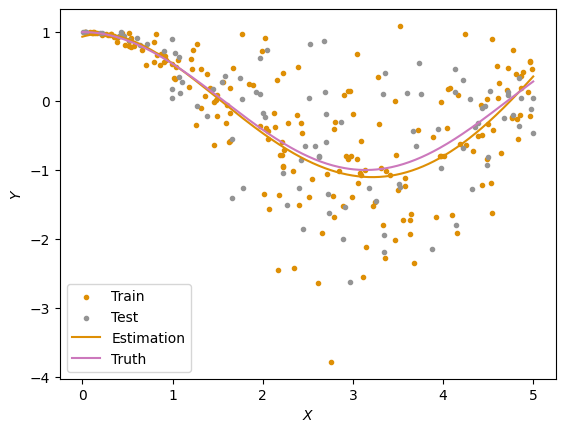

In [ ]:
# Visualization
plt.scatter(X_train,y_train,marker='.',color=color_train,label="Train")
plt.scatter(X_test,y_test,marker='.',color=color_test,label="Test")
aux = np.linspace(0,5,500)
auxpoly = poly.fit_transform(aux[:, np.newaxis])
plt.plot(aux,linear_reg.predict(auxpoly),color=color_train,label="Estimation")
plt.plot(np.linspace(0,5,300),y_true, color = color_true, label = "Truth")

plt.legend()
plt.xlabel(r'$X$')
plt.ylabel(r'$Y$')
plt.show()


In [ ]:
# Some metrics of performance
y_pred = linear_reg.predict(Xpoly_test)
Rtwo_linear_reg = linear_reg.score(Xpoly_test,y_test)
print("R2 for linear regression (polynomial features): ",Rtwo_linear_reg)
RMSE_linear_reg = np.sqrt(np.mean((y_pred-y_test)**2))
print("RMSE for linear regression (polynomial features): ",RMSE_linear_reg)
RMSE_mean = np.sqrt(np.mean((np.mean(y_train)-y_test)**2))
print("RMSE for mean predictor: ",RMSE_mean)

R2 for linear regression (polynomial features):  0.10607616527474928
RMSE for linear regression (polynomial features):  1.333555312434268
RMSE for mean predictor:  1.4117577379283743


# Regression quantile

Nous faisons la même chose avec une régression quantile. Pour rappel, la régression quantile fitte un modèle linéaire sur la fonction quantile d'ordre $\tau$.
Ici, nous choisissons $\beta=0.1$ pour obtenir une couverture d'ordre $1-\beta=0.9$ (donc une couverture à 90%).

On veut un intervalle de prédiction symétrique, on fitte donc les quantiles d'ordre $1-\frac{\beta}{2}$ et $\frac{\beta}{2}$, qui entoure le quantile médian ($\beta=0.5$)

In [ ]:
from sklearn.linear_model import QuantileRegressor

from sklearn.utils.fixes import sp_version, parse_version

## a good idea is to update scipy (!) to avoid problem of convergence
solver = "highs" if sp_version >= parse_version("1.6.0") else "interior-point"



beta = 0.1
qr_down = QuantileRegressor(quantile=beta/2, alpha=0,solver='highs')
qr_up = QuantileRegressor(quantile=1-beta/2, alpha=0,solver='highs')
qr_med = QuantileRegressor(quantile=0.5, alpha=0,solver='highs')

# Fit Upper and Lower Quantile regression and median
qr_down.fit(Xpoly_train, y_train) #TODO LINE
qr_up.fit(Xpoly_train, y_train)   #TODO LINE
qr_med.fit(Xpoly_train, y_train)  #TODO LINE



QuantileRegressor(alpha=0)

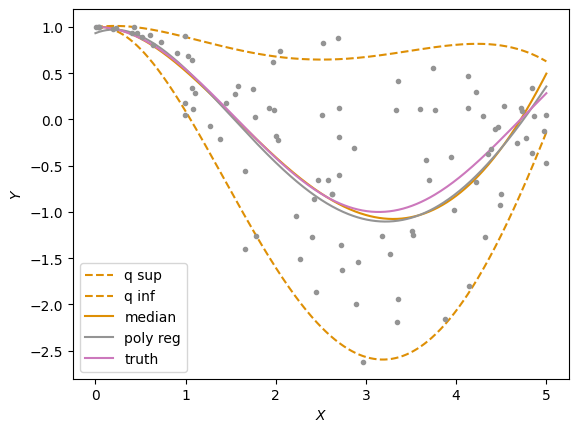

In [ ]:
plt.plot(aux,qr_up.predict(auxpoly),'--',color=color_train,label="q sup")
plt.plot(aux,qr_down.predict(auxpoly),'--',color=color_train,label="q inf")
plt.plot(aux,qr_med.predict(auxpoly),'-',color=color_train,label="median")
plt.plot(aux,linear_reg.predict(auxpoly),'-',color=color_test,label="poly reg")
plt.plot(np.linspace(0,5,300),y_true, color = color_true,label = "truth")

plt.scatter(X_test,y_test,marker='.',color=color_test,zorder=2)
plt.xlabel(r'$X$')
plt.ylabel(r'$Y$')
plt.legend()
#plt.savefig('quantile_reg.pdf', bbox_inches='tight',dpi=300)
plt.show()

# Coverage

Le principal problème que nous allons rencontrer, c'est d'évaluer la couverture réelle du modèle. Autrement dit:
"Si j'ai de nouvelles données, est ce que mes intervalles de prédiction ont bien une couverture d'au moins 90%?"

In [ ]:
y_up_train = qr_up.predict(Xpoly_train)
y_up_test = qr_up.predict(Xpoly_test)
y_down_train = qr_down.predict(Xpoly_train)
y_down_test = qr_down.predict(Xpoly_test)

In [ ]:
# Count how many times the true label was indeed
# in the prediction interval on the test set



# Compute and print theoretical and empirical coverage
theor_cov = 1-beta # TODO OPERAND

prop_covered_qr  = np.sum((y_down_test<=y_test)*(y_test<=y_up_test))/len(y_test) # TODO OPERAND

print("Theoretical coverage: ", theor_cov)
print("Empirical coverage with QR: ", prop_covered_qr)


Theoretical coverage:  0.9
Empirical coverage with QR:  0.8787878787878788


In [ ]:
def coverage_n(n,beta):
  X = np.random.uniform(low=0,high=5,size=n)
  sigma = 0.5
  y = np.cos(X) + (1-np.cos(X))*sigma*np.random.normal(size=n)


  X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.33,
                                                    random_state=42)


  Xpoly_train =  poly.fit_transform(X_train[:, np.newaxis]) # TODO OPERAND
  Xpoly_test  =  poly.fit_transform(X_test[:, np.newaxis])

  qr_down = QuantileRegressor(quantile=beta/2, alpha=0,solver='highs')
  qr_up = QuantileRegressor(quantile=1-beta/2, alpha=0,solver='highs')

  qr_down.fit(Xpoly_train, y_train) #TODO LINE
  qr_up.fit(Xpoly_train, y_train)   #TODO LIN

  y_up_train = qr_up.predict(Xpoly_train)
  y_up_test = qr_up.predict(Xpoly_test)
  y_down_train = qr_down.predict(Xpoly_train)
  y_down_test = qr_down.predict(Xpoly_test)

  prop_covered_qr  = np.sum((y_down_test<=y_test)*(y_test<=y_up_test))/len(y_test) # TODO OPERAND
  return prop_covered_qr


In [ ]:
cov = []
for i in range(200):
  cov.append(coverage_n(1000,0.1))

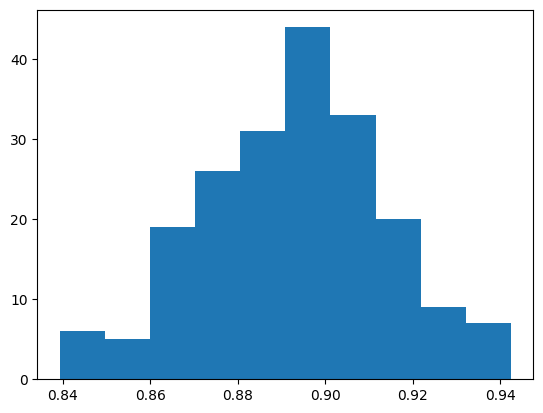

0.8927121212121212


In [ ]:
plt.hist(cov)
plt.show()
print(np.mean(np.array(cov)))

# Applications sur données réelles

On va étudier le jeu de données diamonds, et notamment la relation entre le prix et la taille (en carat) de la pierre.

In [3]:
import seaborn as sns
df = sns.load_dataset("diamonds")
df

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


In [4]:
X = df["carat"].to_numpy()
X

array([0.23, 0.21, 0.23, ..., 0.7 , 0.86, 0.75])

In [5]:
Y = df["price"].to_numpy()
Y

array([ 326,  326,  327, ..., 2757, 2757, 2757])

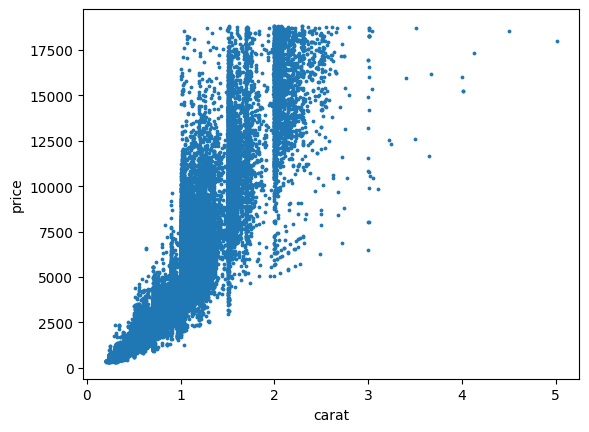

In [6]:
plt.scatter(X,Y,s=3)
plt.xlabel("carat")
plt.ylabel("price")
plt.show()

Il est évident que la distribution ici est hétéroscédastique (la variance conditionnelle n'est pas constante).

On pourrait faire des régression linéaires. Mais, pour rester cohérent avec l'exemple précédent (données générées) on va fitter une régression polynomiale (au vu des "bords convexes" du jeu de données).

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, Y,
                                                    test_size=0.33,
                                                    random_state=42)

In [26]:
from sklearn.linear_model import QuantileRegressor

from sklearn.utils.fixes import sp_version, parse_version

from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(2)
Xpoly_train =  poly.fit_transform(X_train[:, np.newaxis])
Xpoly_test  =  poly.fit_transform(X_test[:, np.newaxis])

## a good idea is to update scipy (!) to avoid problem of convergence
solver = "highs" if sp_version >= parse_version("1.6.0") else "interior-point"



beta = 0.1
qr_down = QuantileRegressor(quantile=beta/2, alpha=0,solver='highs')
qr_up = QuantileRegressor(quantile=1-beta/2, alpha=0,solver='highs')
qr_med = QuantileRegressor(quantile=0.5, alpha=0,solver='highs')

# Fit Upper and Lower Quantile regression and median
qr_down.fit(Xpoly_train, y_train)
qr_up.fit(Xpoly_train, y_train)
qr_med.fit(Xpoly_train, y_train)

QuantileRegressor(alpha=0)

In [27]:
aux = np.linspace(0,X_test.max(),500)
auxpoly = poly.fit_transform(aux[:, np.newaxis])

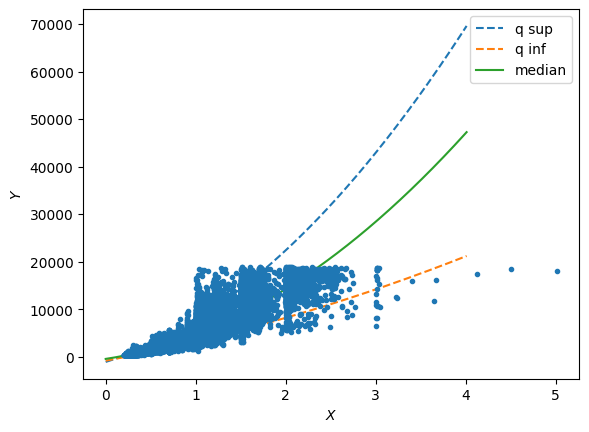

In [28]:
plt.plot(aux,qr_up.predict(auxpoly),'--',label="q sup")
plt.plot(aux,qr_down.predict(auxpoly),'--',label="q inf")
plt.plot(aux,qr_med.predict(auxpoly),'-',label="median")
plt.scatter(X_train,y_train,marker='.',zorder=2)
plt.xlabel(r'$X$')
plt.ylabel(r'$Y$')
plt.legend()

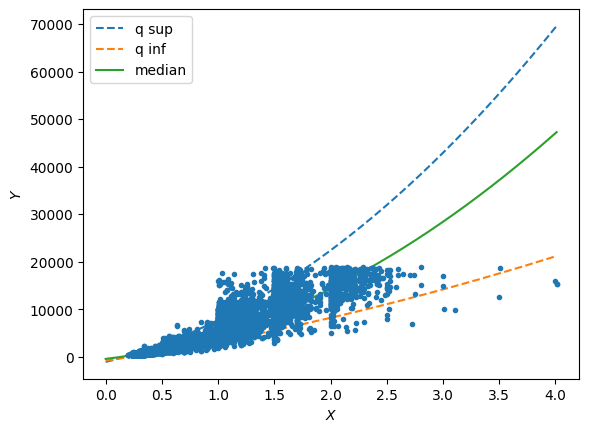

In [29]:
plt.plot(aux,qr_up.predict(auxpoly),'--',label="q sup")
plt.plot(aux,qr_down.predict(auxpoly),'--',label="q inf")
plt.plot(aux,qr_med.predict(auxpoly),'-',label="median")
plt.scatter(X_test,y_test,marker='.',zorder=2)
plt.xlabel(r'$X$')
plt.ylabel(r'$Y$')
plt.legend()

In [9]:
print(f"Size of training test: {len(X_train)}")
print(f"Size of test test: {len(X_test)}")

Size of training test: 36139
Size of test test: 17801


On checke le coverage empirique pour le comparer avec le coverage théorique de 0.9

In [31]:
theor_cov = 1-beta # TODO OPERAND

y_up_train = qr_up.predict(Xpoly_train)
y_up_test = qr_up.predict(Xpoly_test)
y_down_train = qr_down.predict(Xpoly_train)
y_down_test = qr_down.predict(Xpoly_test)

prop_covered_qr  = np.sum((y_down_test<=y_test)*(y_test<=y_up_test))/len(y_test) # TODO OPERAND

print("Theoretical coverage: ", theor_cov)
print("Empirical coverage with QR: ", prop_covered_qr)


Theoretical coverage:  0.9
Empirical coverage with QR:  0.8989944385146902


On constate que la régression quantile est ici efficace. En même temps, cela est plutôt logique : la taille de l'ensemble d'entrainement est très correcte !